[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YOUR-ORG/YOUR-REPO/blob/main/CMPUT328_Assignment2.ipynb)

> In Colab: **Runtime → Change runtime type → GPU**, then run the cells top to bottom.

# CMPUT 328 — Assignment 2, Part 1 (4%)
## CIFAR-10 Classification with a Convolutional Neural Network

**Name:** Yeting Gao
**Student ID:** 1896295

**Deadline:** 8 October 2026, 11:59 PM (Mountain Time)

Submit this notebook with all code, outputs and plots visible, together with the 1–2 page PDF report. Put your name and student ID on both. If you use Gemini or another AI assistant, document how you used it in the report.

### Rubric (each criterion is all-or-nothing)

| # | Component | Weight | Criteria |
| :-- | :-- | :-- | :-- |
| 1 | CNN architecture | 0.5% | Uses conv, ReLU and pooling layers; input stays `N×3×32×32`; flattening only before the classifier |
| 2 | Data pipeline | 0.5% | Provided 45k / 5k / 10k split used unchanged; normalization applied; seeds set |
| 3 | Sanity check | 0.5% | Overfits one 128-image batch to ≥95% accuracy (or loss < 0.1) within 200 iterations; result reported |
| 4 | Tensor shapes | 0.5% | Shape printed after every layer; spatial changes explained using kernel size, stride and padding |
| 5 | Training and curves | 0.5% | 30 epochs with Adam or SGD; per-epoch train/val loss and accuracy plotted; behaviour discussed |
| 6 | Performance | 0.5% | ≥80% validation accuracy at the final epoch with `FAST_MODE = False`; test accuracy reported once |
| 7 | Example predictions | 0.5% | Grid shows true and predicted labels, with both correct and incorrect examples |
| 8 | Interpretation | 0.5% | Discusses error patterns and relates them to the curves and final accuracy |

**Part 1 total = 4%**

### Learning goals
By the end of Part 1 you should be able to:
- Explain why a CNN keeps the image in its spatial form instead of flattening it at the input, and how spatial dimensions change layer to layer.
- Implement a compact CNN (Conv → ReLU → Pool blocks) in PyTorch and train it on CIFAR-10.
- Verify a training pipeline with sanity checks, and read training curves to judge whether a model is learning, underfitting or overfitting.

## 0. Setup
Imports, random seeds and device. **Do not change the seed**: Part 2 relies on the same data split.

In [1]:
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 328

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda


### Run settings
`FAST_MODE` trains on a random subset of the 45,000 training images so the notebook runs quickly while you develop and debug. The validation and test sets are never reduced.

- Use `FAST_MODE = True` for development only.
- **Your submitted results and report must come from a full run with `FAST_MODE = False`.** The performance target in the rubric applies to that run.
- State the setting you used in your report.

In [2]:
FAST_MODE = False              # set to False for your final, graded run
FAST_MODE_TRAIN_SIZE = 10_000 # training images used when FAST_MODE is True
BATCH_SIZE = 128
NUM_WORKERS = 2

Helpers

In [3]:
import os, shutil
from google.colab import drive

drive.mount('/content/drive')
DRIVE_COPY = '/content/drive/MyDrive/cmput328/cifar-10-python.tar.gz'
LOCAL_COPY = './data/cifar-10-python.tar.gz'
os.makedirs('./data', exist_ok=True)

if os.path.exists(DRIVE_COPY):
    shutil.copy(DRIVE_COPY, LOCAL_COPY)   # takes seconds
    print('Copied CIFAR-10 archive from Drive')

def denormalize(img):
    '''Convert a normalized (3, H, W) tensor to an (H, W, 3) array in [0, 1] for plt.imshow.'''
    mean = torch.tensor(cifar_mean).view(3, 1, 1)
    std = torch.tensor(cifar_std).view(3, 1, 1)
    return (img.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

Mounted at /content/drive


## 1. Data loading and normalization (Rubric 2)
The official 50,000 CIFAR-10 training images are split into **45,000 training** and **5,000 validation** images using a fixed seed. The official **10,000-image test set** is kept for final evaluation only.

The training and validation sets are built from two separate dataset objects so that the training-only augmentation (random crop with 4-pixel padding + horizontal flip) never leaks into validation or test. **Save the split indices** to `cifar10_split_seed328.npz` (keys `train_idx` with 45,000 indices and `val_idx` with 5,000 indices, both into the official training set). Part 2 loads this file, so both parts use the identical split. Save the full 45,000 training indices even when `FAST_MODE = True`.

In [4]:
CLASSES = ('airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')

cifar_mean = (0.4914, 0.4822, 0.4465)
cifar_std  = (0.2470, 0.2435, 0.2616)

# Training-only augmentation (same as Part 2): random crop with 4-pixel padding + horizontal flip
train_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(cifar_mean, cifar_std),
])
eval_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(cifar_mean, cifar_std),
])

root = './data'
train_source = datasets.CIFAR10(root, train=True,  download=True, transform=train_tf)
val_source   = datasets.CIFAR10(root, train=True,  download=True, transform=eval_tf)
test_ds      = datasets.CIFAR10(root, train=False, download=True, transform=eval_tf)

# Fixed 45k / 5k split of the official training set
SPLIT_FILE = 'cifar10_split_seed328.npz'   # reused by Part 2 -- do not rename
# TODO: 1) draw a seeded random 45,000 / 5,000 split of the 50,000 training indices
#       2) save it: np.savez(SPLIT_FILE, train_idx=<45,000 indices>, val_idx=<5,000 indices>)
#       3) build train_ds / val_ds from train_source / val_source with these indices
#          (if FAST_MODE, train_ds uses only FAST_MODE_TRAIN_SIZE of the training indices)
rng=np.random.default_rng(SEED)
indices=rng.permutation(len(train_source))
train_idx=indices[:45_000]
val_idx=indices[45_000:]
np.savez(SPLIT_FILE,train_idx=train_idx,val_idx=val_idx)
if FAST_MODE:
  used_train_idx=train_idx[:FAST_MODE_TRAIN_SIZE]
else:
  used_train_idx=train_idx
train_ds=Subset(train_source, used_train_idx.tolist())
val_ds=Subset(val_source, val_idx.tolist())

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

pin = torch.cuda.is_available()
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=pin,
                          worker_init_fn=seed_worker,
                          generator=torch.Generator().manual_seed(SEED))
val_loader   = DataLoader(val_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=pin)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=pin)

print(f'FAST_MODE={FAST_MODE} | train={len(train_ds)}  val={len(val_ds)}  test={len(test_ds)}')

100%|██████████| 170M/170M [27:55<00:00, 102kB/s]


FAST_MODE=False | train=45000  val=5000  test=10000


## 2. CNN architecture  *(Rubric 1)*
Implement a small CNN using convolutional layers, ReLU activations and pooling layers.

- The input must stay in its spatial form (`N × 3 × 32 × 32`) and pass through the convolutional layers first.
- Flattening is allowed **only** after the final convolution/pooling block, immediately before the fully connected classification layer(s).
- Suggested structure: `self.features` (conv/ReLU/pool blocks) followed by `self.classifier` (flatten + linear layers). Keep the model small.
- *Hint for reaching the 80% target:* you may add **BatchNorm** after each convolution and **dropout** in the classifier, and using **two conv layers per block** before each pooling layer (e.g. 3 blocks: 32→16→8→4) helps considerably. A plain 2–3 layer CNN without these usually plateaus in the low-to-mid 70s.

In [5]:
class CIFAR10_CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features=nn.Sequential(
            nn.Conv2d(3,32,kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),)

        self.classifier=nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x=self.features(x)
        x=self.classifier(x)
        return x

## 3. Training and evaluation functions (Rubric 3)
Implement one epoch of training and an evaluation function. Both should return the **average loss** and **accuracy** over the loader.

In [6]:
def train_one_epoch(model, loader, criterion, optimizer):
    '''Train for one epoch. Returns (avg_loss, accuracy).'''
    model.train()
    total_loss=0.0
    total_correct=0
    total_samples=0

    for images,labels in loader:
        images=images.to(device)
        labels=labels.to(device)
        optimizer.zero_grad()
        outputs=model(images)
        loss=criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        batch_size=labels.size(0)
        total_loss+=loss.item()*batch_size
        predictions = outputs.argmax(dim=1)
        total_correct +=(predictions == labels).sum().item()
        total_samples +=batch_size

    avg_loss=total_loss/total_samples
    accuracy=total_correct/total_samples

    return avg_loss,accuracy

@torch.no_grad()
def evaluate(model, loader, criterion):
    '''Evaluate without updating weights. Returns (avg_loss, accuracy).'''
    model.eval()
    total_loss=0.0
    total_correct=0
    total_samples=0
    for images, labels in loader:
        images=images.to(device)
        labels=labels.to(device)
        outputs=model(images)
        loss=criterion(outputs, labels)
        batch_size=labels.size(0)
        total_loss+=loss.item()*batch_size

        predictions=outputs.argmax(dim=1)
        total_correct+= (predictions==labels).sum().item()
        total_samples+= batch_size
    avg_loss=total_loss/total_samples
    accuracy=total_correct/total_samples
    return avg_loss, accuracy

## 4. Tensor shape check  *(Rubric 4)*
Pass a sample batch through the network and print the tensor shape after **every** layer (convolution, activation, pooling, flatten and linear).

*Hint:* iterate over the layers in `self.features` and `self.classifier`, or register forward hooks.

In [7]:
set_seed()
model = CIFAR10_CNN().to(device)
x = torch.randn(4, 3, 32, 32, device=device)

print(f'{"Input":30s} {tuple(x.shape)}')

#TODO: print the tensor shape of each layer
with torch.no_grad():
    for layer in model.features:
        x=layer(x)
        print(layer.__class__.__name__,x.shape)

    for layer in model.classifier:
        x=layer(x)
        print(layer.__class__.__name__, x.shape)

Input                          (4, 3, 32, 32)
Conv2d torch.Size([4, 32, 32, 32])
BatchNorm2d torch.Size([4, 32, 32, 32])
ReLU torch.Size([4, 32, 32, 32])
Conv2d torch.Size([4, 32, 32, 32])
BatchNorm2d torch.Size([4, 32, 32, 32])
ReLU torch.Size([4, 32, 32, 32])
MaxPool2d torch.Size([4, 32, 16, 16])
Conv2d torch.Size([4, 64, 16, 16])
BatchNorm2d torch.Size([4, 64, 16, 16])
ReLU torch.Size([4, 64, 16, 16])
Conv2d torch.Size([4, 64, 16, 16])
BatchNorm2d torch.Size([4, 64, 16, 16])
ReLU torch.Size([4, 64, 16, 16])
MaxPool2d torch.Size([4, 64, 8, 8])
Conv2d torch.Size([4, 128, 8, 8])
BatchNorm2d torch.Size([4, 128, 8, 8])
ReLU torch.Size([4, 128, 8, 8])
Conv2d torch.Size([4, 128, 8, 8])
BatchNorm2d torch.Size([4, 128, 8, 8])
ReLU torch.Size([4, 128, 8, 8])
MaxPool2d torch.Size([4, 128, 4, 4])
Flatten torch.Size([4, 2048])
Linear torch.Size([4, 256])
ReLU torch.Size([4, 256])
Dropout torch.Size([4, 256])
Linear torch.Size([4, 10])


**Explain the shape changes.** Since the convolutions use kernel size 3, stride 1 and padding 1, so height and width stay unchanged. The blocks output 32, 64 and 128 channels. Max pooling uses kernel size 2, stride 2 and no padding, reducing the spatial size from 32 to 16, 8 and 4. Flatten produces 128 * 4 * 4=2048 features per image. Linear layers map the feature dimensions sequentially from 2,048 to 256 and then to 10. BatchNorm, ReLU, and Dropout operations do not alter the tensor shape, and the batch size remains 4.

## 5. Sanity check: overfit one batch  *(Rubric 3)*
Train a **fresh** model on a single fixed batch of 128 training images for up to 200 iterations.

The check passes if training accuracy on the batch reaches **at least 95%** or the loss falls **below 0.1**. Report the final loss and accuracy. If it fails, fix your model or training loop before continuing.

In [8]:
set_seed()
sanity_images, sanity_labels = next(iter(DataLoader(train_ds, batch_size=128, shuffle=False)))
sanity_images, sanity_labels = sanity_images.to(device), sanity_labels.to(device)

# Fresh, untrained model just for this check
sanity_model = CIFAR10_CNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(sanity_model.parameters(), lr=1e-3)

# YOUR CODE GOES HERE
sanity_model.train()
for step in range(200):
    optimizer.zero_grad()
    outputs=sanity_model(sanity_images)
    loss=criterion(outputs, sanity_labels)
    loss.backward()
    optimizer.step()
    acc=(outputs.argmax(1) == sanity_labels).float().mean().item()
    if (step+1)%20 == 0:
        print(f"Step {step + 1}:loss={loss.item():.4f},acc={acc:.2%}")
    if acc >= 0.95 or loss.item() < 0.1:
        break

print(f"Final: step={step+1},loss={loss.item():.4f},acc={acc:.2%}")
print("Passed:", acc >= 0.95 or loss.item() < 0.1)

Final: step=14,loss=0.3461,acc=98.44%
Passed: True


The model reached 98.44% accuracy with a loss of 0.3461 on the fixed batch of 128 images after 14 iterations. The sanity check passed.

## 6. Full training  *(Rubric 5)*
Train a fresh model for **30 epochs** with Adam or SGD. After each epoch, record training and validation loss and accuracy in `history`.

**Do not evaluate on the test set during training.** Record the time per epoch as well.

In [9]:
set_seed()
model = CIFAR10_CNN().to(device)
EPOCHS = 30

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'epoch_time': []}

## YOUR CODE GOES HERE
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(EPOCHS):
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()

    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc = evaluate(model, val_loader, criterion)

    if device.type == 'cuda':
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['epoch_time'].append(elapsed)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"train loss={train_loss:.4f}, acc={train_acc:.2%} | "
        f"val loss={val_loss:.4f}, acc={val_acc:.2%} | "
        f"time={elapsed:.1f}s"
    )

Epoch 1/30 | train loss=1.5543, acc=42.60% | val loss=1.2674, acc=55.12% | time=23.3s
Epoch 2/30 | train loss=1.1028, acc=60.76% | val loss=0.9366, acc=66.24% | time=23.3s
Epoch 3/30 | train loss=0.9186, acc=67.52% | val loss=0.8986, acc=68.80% | time=23.2s
Epoch 4/30 | train loss=0.8182, acc=71.18% | val loss=0.7590, acc=74.10% | time=23.2s
Epoch 5/30 | train loss=0.7522, acc=74.11% | val loss=0.6935, acc=76.14% | time=23.3s
Epoch 6/30 | train loss=0.6947, acc=76.08% | val loss=0.6362, acc=78.42% | time=22.4s
Epoch 7/30 | train loss=0.6489, acc=78.05% | val loss=0.6732, acc=75.92% | time=23.9s
Epoch 8/30 | train loss=0.6178, acc=78.77% | val loss=0.6243, acc=78.38% | time=22.3s
Epoch 9/30 | train loss=0.5819, acc=80.31% | val loss=0.6315, acc=77.92% | time=24.4s
Epoch 10/30 | train loss=0.5511, acc=81.38% | val loss=0.5324, acc=81.90% | time=22.1s
Epoch 11/30 | train loss=0.5206, acc=82.52% | val loss=0.4994, acc=83.28% | time=24.2s
Epoch 12/30 | train loss=0.5025, acc=82.98% | val lo

### Save the trained model (recommended, not graded)
Saving the weights lets you reuse this CNN in Part 2 without retraining.

In [10]:
## YOUR CODE GOES HERE
checkpoint = {
      'model_state_dict': model.state_dict(),
      'optimizer_state_dict': optimizer.state_dict(),
      'epoch': EPOCHS,
      'history': history,
}
torch.save(checkpoint,'YOUR_CHECKPOINT.pt')
print(f'Saved checkpoint after {EPOCHS} epochs')

Saved checkpoint after 30 epochs


## 7. Training curves
Plot training and validation loss on one graph, and training and validation accuracy on another, both against epochs.

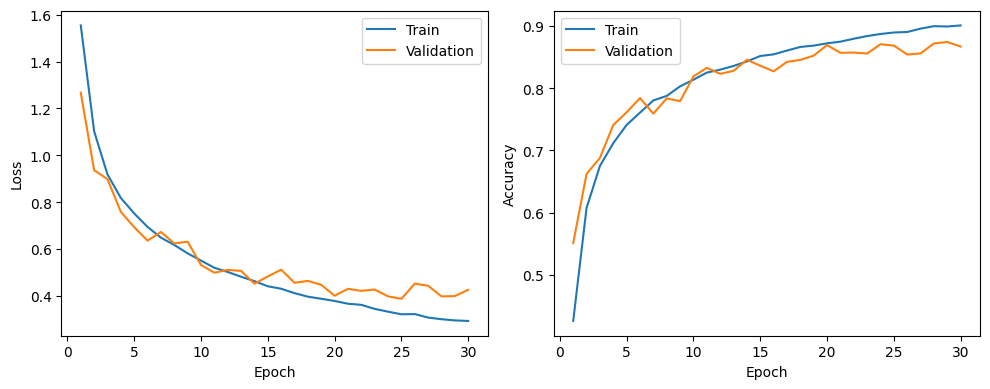

In [11]:
# YOUR CODE GOES HERE
epochs=range(1,len(history['train_loss'])+1)
plt.figure(figsize=(10, 4))

plt.subplot(1,2,1)
plt.plot(epochs, history['train_loss'], label='Train')
plt.plot(epochs, history['val_loss'], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(epochs, history['train_acc'], label='Train')
plt.plot(epochs, history['val_acc'], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

**Discuss the training behaviour.** Is the model learning? Is there evidence of underfitting or overfitting?

The model is learning because the training loss goes down and both accuracies improve overall. It finishes with 90.10% training accuracy and 86.70% validation accuracy. The training accuracy is a little higher, and the validation loss goes up and down near the end. This suggests some mild overfitting, but the validation results are still good.

## 8. Final evaluation  *(Rubric 6)*
Report the final validation accuracy, then evaluate **once** on the 10,000-image test set and report the test accuracy.

Target: at least **80% validation accuracy** at the final epoch with `FAST_MODE = False`.

In [12]:
## YOUR CODE GOES HERE
print(f"Final validation accuracy: {history['val_acc'][-1]:.2%}")
test_loss,test_acc=evaluate(model,test_loader,criterion)
print(f"Test loss:{test_loss:.4f}")
print(f"Test accuracy:{test_acc:.2%}")

Final validation accuracy: 86.70%
Test loss:0.4442
Test accuracy:86.06%


## 9. Example predictions  *(Rubric 7)*
Show a grid of validation images with their true and predicted classes. Include **at least 8 correct and 8 incorrect** predictions.

Use `denormalize` to convert images back to a displayable range.

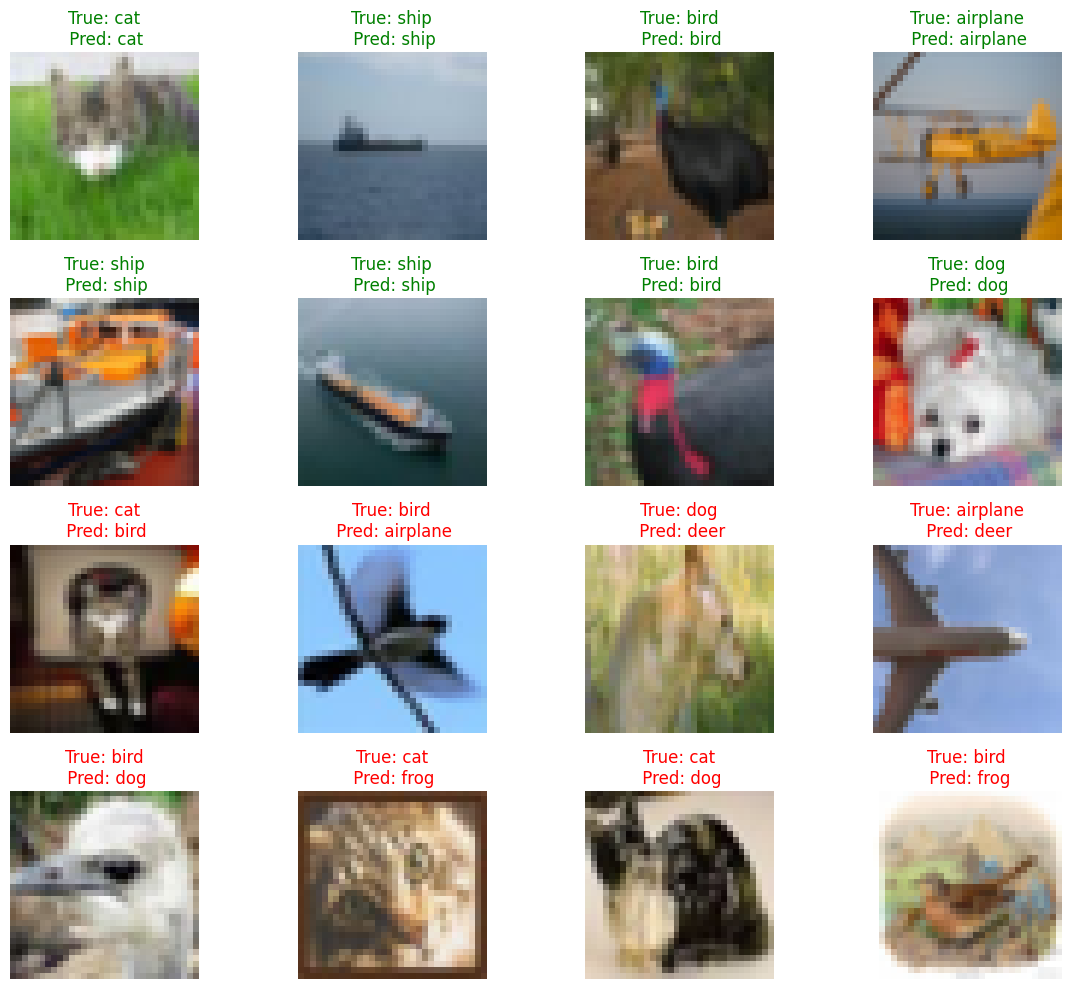

In [13]:
## YOUR CODE GOES HERE
model.eval()
correct,incorrect=[],[]
with torch.no_grad():
    for images,labels in val_loader:
        predictions=model(images.to(device)).argmax(1).cpu()
        for image,label,prediction in zip(images,labels,predictions):
            group=correct if label.item()==prediction.item() else incorrect
            if len(group)<8:
                group.append((image,label.item(),prediction.item()))
        if len(correct)==8 and len(incorrect)==8:
            break
examples=correct+incorrect
fig,axes=plt.subplots(4,4,figsize=(12,10))
for ax,(image,label,prediction) in zip(axes.flat,examples):
    ax.imshow(denormalize(image))
    ax.set_title(f"True: {CLASSES[label]}\n Pred: {CLASSES[prediction]}",color='green' if label==prediction else 'red')
    ax.axis('off')

plt.tight_layout()
plt.show()

## 10. Interpretation  *(Rubric 8)*
Using the example predictions, discuss which classes the model confuses and suggest reasons, such as visual similarity or low resolution. Relate this to the curves and the final test accuracy.
The model confuses a cat with a bird, a dog and a frog, a dog with a deer, and a bird with an airplane and a frog and a dog, and an airplane with a deer. These mistakes may be caused by similar shapes, colours and backgrounds. Because of the low resolution in blurry and close-up images, it makes details difficult to distinguish. The training results show overall improvement with a small gap. The test accuracy of 86.06% is close to the validation accuracy of 86.70%, suggesting that the model generalizes reasonably well despite some ambiguous images.

### Notes on Part 1 - Check that:
- [ ] Final run uses `FAST_MODE = False`, and the setting is stated in the report
- [ ] All cells run top to bottom without errors, with outputs and plots visible
- [ ] AI assistance (if any) is documented in the report


# CMPUT 328 — Assignment 2, Part 2 (5%)
## CIFAR-10 Classification with a ViT and LoRA Fine-Tuning

**Goal.** Train a compact Vision Transformer (ViT) from scratch on CIFAR-10, fine-tune an ImageNet-pretrained ViT with LoRA, and compare both against your Part 1 CNN, a linear probe and full fine-tuning in terms of accuracy and training cost.

| Section | Content |
|---|---|
| 1 | Data pipeline (45k / 5k / 10k split, seeds) |
| 2 | ViT from scratch, sanity checks, training |
| 3 | Training curves, CNN comparison |
| 4 | Pretrained ViT + linear probe |
| 5 | LoRA vs. full fine-tuning |
| 6 | Results table, confusion matrices, misclassified images |
| 7 | Controlled experiment |

### Rubric (each criterion is all-or-nothing)

| # | Component | Weight | Criteria |
| :-- | :-- | :-- | :-- |
| 1 | Data pipeline | 0.4% | 45,000 / 5,000 / 10,000 split correctly drawn from the official CIFAR-10 train/test sets and documented; all random seeds set (`torch.manual_seed`, `random.seed`, `np.random.seed`, e.g. 328) |
| 2 | Vision Transformer from scratch | 0.8% | Image is split into patches and tokenized (not flattened whole); includes patch embedding, learnable [CLS] token, positional embeddings, a stack of Transformer encoder blocks and a classification head. Both sanity checks present: tiny-batch overfit to near-100% accuracy, and tensor shapes printed after each stage. Trained 20–30 epochs with Adam/AdamW at a reasonable LR |
| 3 | Training dynamics and CNN comparison | 0.6% | Loss/accuracy plots included. CNN re-run on the identical split and a comparable epoch budget; test accuracy reported |
| 4 | Loading an ImageNet-pretrained ViT | 0.4% | Pretrained ViT loaded correctly with a new 10-class head; images resized to 224×224 and normalized with the pretrained model's stats. Backbone fully frozen for the linear probe (1–2 epochs); test accuracy reported |
| 5 | LoRA fine-tuning | 0.8% | LoRA adapters injected into attention projections via `peft`, with a stated rank; classification head kept trainable. Full fine-tuning run with the same epoch budget. All four quantities reported for both: trainable params (and %), time/epoch, peak GPU memory, test accuracy |
| 6 | Results comparison | 0.6% | Summary table across all models. Confusion matrices for both scratch ViT and LoRA. Grid of ≥16 misclassified LoRA images with predicted/true labels |
| 7 | Controlled experiment | 0.4% | One deliberate, clearly stated change, run and reported |
| — | Report | 1.0% | See the assignment description |

**Part 2 total = 5%**

**How to run.** Use a GPU runtime (Colab T4 or better). The 224×224 ViT-Base runs (sections 4, 5, 7) dominate the runtime. If it is too slow, or full fine-tuning runs out of memory, lower `PT_N_TRAIN` / `PT_BATCH` in the config cell and state what you changed in your report.

Fill in every `## YOUR CODE GOES HERE` / `# TODO` block, run the notebook top to bottom, and answer the ✏️ discussion cells using your own numbers and plots.

In [14]:
%pip install -q transformers peft scikit-learn pandas matplotlib

In [15]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [16]:
import copy, gc, math, os, random, time
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
import torchvision.transforms as T
from torchvision.datasets import CIFAR10
from sklearn.metrics import confusion_matrix

try:
    from IPython.display import display
except ImportError:  # plain-python fallback
    display = print

# ------------------------------------------------------------------ config
SMOKE = False   # True = tiny subsets / 1 epoch, only to check that the code runs end-to-end
SEED = 328
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ROOT = "./data"                        # same folder as Part 1
NUM_WORKERS = 0 if SMOKE else 2       # set to 0 if you hit multiprocessing errors on Windows

# split sizes (train/val come from the 50k official training set; test = official 10k test set)
N_TRAIN, N_VAL, N_TEST = 45_000, 5_000, 10_000

# --- from-scratch ViT and CNN
EPOCHS_SCRATCH = 30                    # assignment: 20-30 epochs
BATCH_SCRATCH = 128
LR_VIT = 3e-4
EPOCHS_CNN = 30                        # comparable budget to the ViT
LR_CNN = 1e-3

# --- pretrained ViT-Base @ 224x224 (expensive: lower PT_N_TRAIN / PT_BATCH if needed)
PT_NAME = "google/vit-base-patch16-224-in21k"
PT_N_TRAIN, PT_N_VAL, PT_N_TEST = 45_000, 5_000, 10_000   # e.g. PT_N_TRAIN = 15_000 to go ~3x faster
PT_BATCH = 64
EPOCHS_LP = 2                          # linear probe: 1-2 epochs
EPOCHS_FT = 3                          # LoRA and full FT share this budget (2-3 epochs)
LR_LP, LR_LORA, LR_FULL = 2e-3, 1e-3, 2e-5
LORA_R = 8

OVERFIT_STEPS = 300

if SMOKE:
    N_TRAIN, N_VAL, N_TEST = 512, 256, 256
    EPOCHS_SCRATCH = EPOCHS_CNN = EPOCHS_LP = EPOCHS_FT = 1
    PT_N_TRAIN, PT_N_VAL, PT_N_TEST, PT_BATCH = 32, 16, 16, 16
    OVERFIT_STEPS = 30

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed()
print(f"torch {torch.__version__} | device: {DEVICE} | seed: {SEED}")
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

torch 2.11.0+cu130 | device: cuda | seed: 328
GPU: Tesla T4


## 1. Data pipeline  *(Rubric 1)*

Part 2 uses **the same 45,000 / 5,000 train/validation split as Part 1**, loaded from `cifar10_split_seed328.npz` (saved in Part 1, section 1), and the **official 10,000 test images** for final reporting only. All models in Part 2 (ViT, CNN, linear probe, LoRA, full fine-tuning) must use **exactly this split**. Seeds are already set in the config cell above.

> The `.npz` file lives on the Colab VM disk: it survives a runtime restart, but not a disconnect or a runtime reset. If it is missing, re-run Part 1's setup and section 1 first.

`make_loaders` (provided) builds the train/val/test loaders for a given normalization from `TRAIN_IDX` and `VAL_IDX`:
- Models trained from scratch use the CIFAR-10 channel mean/std.
- The pretrained ViT uses the mean/std of its image processor (section 4).
- Augmentation is applied to the training set only; validation and test are never augmented.

 **Document your split here:** how the indices were drawn in Part 1, which seed was used, and which images go to train / validation / test.

 I used seed 328 to randomly shuffle the 50,000 official training indices with NumPy's default_rng. I used the first 45,000 for training and the other 5,000 for validation. I saved these indices and loaded the same file in Part 2, so all models use the same split. The official 10,000 test images are used for final evaluation. The training and validation sets do not overlap.

In [17]:
CIFAR_MEAN, CIFAR_STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)

raw_train = CIFAR10(ROOT, train=True, download=True)      # un-transformed, used to display images
CLASSES = raw_train.classes

SPLIT_FILE = "cifar10_split_seed328.npz"    # saved in Part 1, section 1
if not os.path.exists(SPLIT_FILE):
    raise FileNotFoundError(f"{SPLIT_FILE} not found - run Part 1, section 1 first.")

# TODO: load `train_idx` and `val_idx` from SPLIT_FILE into TRAIN_IDX and VAL_IDX (as Python lists of ints)
#       and check that they have 45,000 and 5,000 elements.
## YOUR CODE GOES HERE
split=np.load(SPLIT_FILE)
TRAIN_IDX=split['train_idx'].tolist()
VAL_IDX=split['val_idx'].tolist()

assert len(TRAIN_IDX)==45000
assert len(VAL_IDX)==5000
assert len(set(TRAIN_IDX)&set(VAL_IDX))==0


def make_loaders(mean, std, aug, batch_size, n_train, n_val, n_test):
    """Train (augmented, shuffled), val and test (deterministic) loaders for a given normalization."""
    norm = [T.ToTensor(), T.Normalize(mean, std)]
    train_tf, eval_tf = T.Compose(aug + norm), T.Compose(norm)
    ds_train = CIFAR10(ROOT, train=True, transform=train_tf)
    ds_eval = CIFAR10(ROOT, train=True, transform=eval_tf)
    ds_test = CIFAR10(ROOT, train=False, transform=eval_tf)
    g = torch.Generator().manual_seed(SEED)
    kw = dict(num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda")
    train_loader = DataLoader(Subset(ds_train, TRAIN_IDX[:n_train]), batch_size, shuffle=True, generator=g,
                              worker_init_fn=lambda w: np.random.seed(SEED + w), **kw)
    val_loader = DataLoader(Subset(ds_eval, VAL_IDX[:n_val]), batch_size * 2, shuffle=False, **kw)
    test_loader = DataLoader(Subset(ds_test, list(range(n_test))), batch_size * 2, shuffle=False, **kw)
    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = make_loaders(
    CIFAR_MEAN, CIFAR_STD, [T.RandomCrop(32, padding=4), T.RandomHorizontalFlip()],
    BATCH_SCRATCH, N_TRAIN, N_VAL, N_TEST)

targets = np.array(raw_train.targets)
print(f"train: {len(train_loader.dataset)} | val: {len(val_loader.dataset)} | test: {len(test_loader.dataset)}")
print("train/val overlap:", len(set(TRAIN_IDX) & set(VAL_IDX)))
print("val class counts  :", np.bincount(targets[VAL_IDX[:N_VAL]], minlength=10))
print("train class counts:", np.bincount(targets[TRAIN_IDX[:N_TRAIN]], minlength=10))

train: 45000 | val: 5000 | test: 10000
train/val overlap: 0
val class counts  : [544 530 524 515 459 498 438 479 515 498]
train class counts: [4456 4470 4476 4485 4541 4502 4562 4521 4485 4502]


## 2. Vision Transformer from scratch  *(Rubric 2)*

Implement a compact ViT for 32×32 CIFAR-10 images. **Do not flatten the whole image at the input** — split it into patches and tokenize them. Your model must include:

1. **Patch embedding** — cut the image into non-overlapping patches (e.g. 4×4 → 8×8 = 64 patches) and project each patch to a `dim`-dimensional token. *Hint:* a `Conv2d` with `kernel_size = stride = patch` is equivalent to flattening each patch and applying a shared linear layer.
2. A learnable **[CLS]** token prepended to the patch tokens.
3. Learnable **positional embeddings** added to all tokens.
4. A stack of **Transformer encoder blocks** (e.g. pre-norm: `x = x + MHSA(LN(x))`, `x = x + MLP(LN(x))`).
5. A final LayerNorm, then a **linear classification head** on the [CLS] token (10 classes).

Suggested size (a few million parameters): `dim=256, depth=8, heads=8, mlp_ratio=2, drop=0.1`. Keep the constructor signature below; later cells call `ViT()` and `ViT(drop=0.0)`.

When `verbose=True`, `ViT.forward` should print the tensor shape after **each stage** (used for sanity check (b)).

In [18]:
class PatchEmbed(nn.Module):
    def __init__(self, patch=4, in_ch=3, dim=256):
        super().__init__()
        self.proj=nn.Conv2d(in_ch,dim,kernel_size=patch,stride=patch)

    def forward(self, x):
        # x: (B, 3, 32, 32)  ->  return a sequence of patch tokens of shape (B, num_patches, dim)
        ## YOUR CODE GOES HERE
        x=self.proj(x)
        return x.flatten(2).transpose(1,2)


class Attention(nn.Module):
    '''Multi-head self-attention.'''
    def __init__(self, dim, heads, drop):
        super().__init__()
        ## YOUR CODE GOES HERE
        self.attn=nn.MultiheadAttention(dim,heads,dropout=drop,batch_first=True)

    def forward(self, x):
        # x: (B, N, dim) -> (B, N, dim)
        ## YOUR CODE GOES HERE
        return self.attn(x,x,x,need_weights=False)[0]


class Block(nn.Module):
    '''One Transformer encoder block: attention + MLP, each with LayerNorm and a residual connection.'''
    def __init__(self, dim, heads, mlp_ratio, drop):
        super().__init__()
        ## YOUR CODE GOES HERE
        self.norm1=nn.LayerNorm(dim)
        self.attn=Attention(dim,heads,drop)
        self.norm2=nn.LayerNorm(dim)
        self.mlp=nn.Sequential(nn.Linear(dim,dim*mlp_ratio),nn.GELU(),nn.Dropout(drop),nn.Linear(dim*mlp_ratio,dim),nn.Dropout(drop))

    def forward(self, x):
        ## YOUR CODE GOES HERE
        x=x+self.attn(self.norm1(x))
        x=x+self.mlp(self.norm2(x))
        return x


class ViT(nn.Module):
    def __init__(self, img=32, patch=4, dim=256, depth=8, heads=8, mlp_ratio=2, n_classes=10, drop=0.1):
        super().__init__()
        # TODO: patch embedding, learnable [CLS] token, learnable positional embeddings,
        #       a stack of `depth` encoder blocks, final LayerNorm and a linear classification head.
        ## YOUR CODE GOES HERE
        self.patch_embed=PatchEmbed(patch,3,dim)
        num_patches=(img//patch)**2

        self.cls_token=nn.Parameter(torch.zeros(1,1,dim))
        self.pos_embed=nn.Parameter(torch.zeros(1,num_patches+1,dim))
        nn.init.normal_(self.cls_token,std=0.02)
        nn.init.normal_(self.pos_embed,std=0.02)

        self.dropout=nn.Dropout(drop)
        self.blocks=nn.ModuleList([Block(dim,heads,mlp_ratio,drop)for _ in range(depth)])
        self.norm=nn.LayerNorm(dim)
        self.head=nn.Linear(dim,n_classes)

    def forward(self, x, verbose=False):
        log = (lambda name, t: print(f"{name:<34}{tuple(t.shape)}")) if verbose else (lambda *a: None)
        log("input image", x)
        # TODO: patch embedding -> prepend [CLS] -> + positional embedding -> encoder blocks
        #       -> final LayerNorm -> take [CLS] token -> classification head.
        #       Call log(...) after every stage so the shapes are printed when verbose=True.
        ## YOUR CODE GOES HERE
        x=self.patch_embed(x)
        log("patch embedding",x)

        cls=self.cls_token.expand(x.size(0),-1,-1)
        x=torch.cat((cls,x),dim=1)
        log("prepend CLS token",x)

        x=x+self.pos_embed
        log("positional embedding",x)

        x=self.dropout(x)
        log("dropout",x)

        for i,block in enumerate(self.blocks):
            x=block(x)
            log(f"encoder block {i+1}",x)

        x=self.norm(x)
        log("final LayerNorm",x)

        x=x[:,0]
        log("CLS token",x)

        x=self.head(x)
        log("classification head",x)
        return x


def count_params(model):
    '''Returns (number of trainable parameters, total number of parameters).'''
    ## YOUR CODE GOES HERE
    trainable=sum(p.numel() for p in model.parameters() if p.requires_grad)
    total=sum(p.numel() for p in model.parameters())
    return trainable,total


vit = ViT().to(DEVICE)
print(f"ViT parameters: {count_params(vit)[1] / 1e6:.2f} M")

ViT parameters: 4.25 M


### Sanity check (b): tensor shapes after every stage

In [19]:
vit.eval()
with torch.no_grad():
    _ = vit(torch.randn(4, 3, 32, 32, device=DEVICE), verbose=True)

input image                       (4, 3, 32, 32)
patch embedding                   (4, 64, 256)
prepend CLS token                 (4, 65, 256)
positional embedding              (4, 65, 256)
dropout                           (4, 65, 256)
encoder block 1                   (4, 65, 256)
encoder block 2                   (4, 65, 256)
encoder block 3                   (4, 65, 256)
encoder block 4                   (4, 65, 256)
encoder block 5                   (4, 65, 256)
encoder block 6                   (4, 65, 256)
encoder block 7                   (4, 65, 256)
encoder block 8                   (4, 65, 256)
final LayerNorm                   (4, 65, 256)
CLS token                         (4, 256)
classification head               (4, 10)


### Training utilities (shared by every model in this notebook)

* `evaluate` (provided) — returns average loss, accuracy, predictions and labels over a loader.
* `fit` — **implement it.** Train with AdamW over the *trainable* parameters only, and record per epoch: training loss & accuracy, validation loss & accuracy, and the wall-clock time of the **training part** of the epoch. Optional but recommended: linear LR warm-up then cosine decay, gradient clipping, and mixed precision (`torch.autocast` + `GradScaler`) on GPU.
* `run_experiment` — trains a model, then measures test accuracy, trainable parameters, mean time per epoch and **peak GPU memory** (`torch.cuda.max_memory_allocated()`), and stores everything for the final table. **Complete the TODOs.**

In [20]:
def sync():
    if DEVICE.type == "cuda": torch.cuda.synchronize()

@torch.no_grad()
def evaluate(model, loader, amp=True):
    model.eval()
    crit = nn.CrossEntropyLoss(reduction="sum")
    loss_sum, preds, labels = 0.0, [], []
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp and DEVICE.type == "cuda"):
            logits = model(x)
        loss_sum += crit(logits.float(), y).item()
        preds.append(logits.argmax(1).cpu()); labels.append(y.cpu())
    preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()
    return loss_sum / len(labels), float((preds == labels).mean()), preds, labels


def fit(model, train_loader, val_loader, epochs, lr, weight_decay=0.0, warmup_frac=0.05, clip=1.0, amp=True, name=""):
    '''Train `model` and return a history dict with lists:
       'train_loss', 'train_acc', 'val_loss', 'val_acc', 'epoch_time' (one entry per epoch).
    '''
    params = [p for p in model.parameters() if p.requires_grad]   # only trainable params (linear probe / LoRA!)
    hist = defaultdict(list)
    # TODO:
    #   1. Create an AdamW optimizer over `params` (optionally an LR scheduler: warm-up + cosine decay).
    #   2. For each epoch: train over train_loader, timing ONLY the training part
    #      (call sync() before reading time.perf_counter()).
    #   3. Evaluate on val_loader with `evaluate`, append all five quantities to `hist`, and print a one-line summary.
    ## YOUR CODE GOES HERE
    optimizer=torch.optim.AdamW(params,lr=lr,weight_decay=weight_decay)
    criterion=nn.CrossEntropyLoss()
    use_amp=amp and DEVICE.type=="cuda"
    scaler=torch.amp.GradScaler("cuda",enabled=use_amp)

    for epoch in range(epochs):
        model.train()
        loss_sum,correct,total=0.0,0,0
        sync()
        start=time.perf_counter()

        for x,y in train_loader:
            x=x.to(DEVICE)
            y=y.to(DEVICE)
            optimizer.zero_grad()

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=use_amp
            ):
                outputs=model(x)
                loss=criterion(outputs,y)

            scaler.scale(loss).backward()
            if clip is not None and clip>0:
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(params,clip)
            scaler.step(optimizer)
            scaler.update()

            loss_sum+=loss.item()*y.size(0)
            correct+=(outputs.argmax(1)==y).sum().item()
            total+=y.size(0)

        sync()
        elapsed=time.perf_counter()-start

        val_loss,val_acc,_,_=evaluate(model,val_loader,amp=amp)
        hist["train_loss"].append(loss_sum/total)
        hist["train_acc"].append(correct/total)
        hist["val_loss"].append(val_loss)
        hist["val_acc"].append(val_acc)
        hist["epoch_time"].append(elapsed)

        print(
            f"{name} Epoch {epoch+1}/{epochs} | "
            f"train loss={loss_sum/total:.4f},acc={correct/total:.2%} | "
            f"val loss={val_loss:.4f},acc={val_acc:.2%} | "
            f"time={elapsed:.1f}s"
        )
    return dict(hist)


RESULTS, HISTORY, VAL_PREDS = {}, {}, {}      # filled by run_experiment; used in sections 3, 6, 7

def cleanup():
    gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()

def run_experiment(name, model, loaders, epochs, lr, weight_decay=0.0):
    tr, va, te = loaders
    model.to(DEVICE)
    trainable, total = count_params(model)
    print(f"\n=== {name} | trainable {trainable:,} / {total:,} ({100 * trainable / total:.2f}%) ===")
    # TODO: reset the peak GPU memory counter before training (only if DEVICE is cuda)
    ## YOUR CODE GOES HERE
    if DEVICE.type=="cuda":
        torch.cuda.reset_peak_memory_stats()

    hist = fit(model, tr, va, epochs, lr, weight_decay, name=name)

    # TODO: read the peak GPU memory in MB after training (use float("nan") on CPU)
    ## YOUR CODE GOES HERE
    peak=(
        torch.cuda.max_memory_allocated()/1024**2
        if DEVICE.type=="cuda"
        else float("nan")
    )

    _, val_acc, val_pred, val_lab = evaluate(model, va)
    _, test_acc, _, _ = evaluate(model, te)
    RESULTS[name] = dict(test_acc=100 * test_acc, val_acc=100 * val_acc, trainable=trainable, total=total,
                         pct_trainable=100 * trainable / total, sec_per_epoch=float(np.mean(hist["epoch_time"])),
                         peak_mem_mb=peak, epochs=epochs)
    HISTORY[name], VAL_PREDS[name] = hist, (val_pred, val_lab)
    print(f"--> {name}: test acc {100 * test_acc:.2f}% | {RESULTS[name]['sec_per_epoch']:.1f} s/epoch | peak mem {peak:.0f} MB")
    return hist

### Sanity check (a): overfit a tiny batch

Train a **fresh** ViT (no dropout) on a single fixed batch of 128 training images (no augmentation) for `OVERFIT_STEPS` iterations. If the model, loss, optimizer and data plumbing are correct, the loss should go to ~0 and the accuracy to ~100%. Print the loss and accuracy periodically and report the final accuracy.

In [21]:
set_seed()
tiny_ds = Subset(CIFAR10(ROOT, train=True, transform=T.Compose([T.ToTensor(), T.Normalize(CIFAR_MEAN, CIFAR_STD)])), TRAIN_IDX[:128])
xb, yb = next(iter(DataLoader(tiny_ds, batch_size=128)))
xb, yb = xb.to(DEVICE), yb.to(DEVICE)

tiny_model = ViT(drop=0.0).to(DEVICE)
opt = torch.optim.Adam(tiny_model.parameters(), lr=1e-3)

## YOUR CODE GOES HERE
criterion=nn.CrossEntropyLoss()
tiny_model.train()

for step in range(OVERFIT_STEPS):
    opt.zero_grad()
    outputs=tiny_model(xb)
    loss=criterion(outputs,yb)
    loss.backward()
    opt.step()

    if (step+1)%50==0:
        acc=(outputs.argmax(1)==yb).float().mean().item()
        print(f"Step {step+1}:loss={loss.item():.4f},acc={acc:.2%}")

tiny_model.eval()
with torch.no_grad():
    outputs=tiny_model(xb)
    loss=criterion(outputs,yb)
    acc=(outputs.argmax(1)==yb).float().mean().item()

print(f"Final:loss={loss.item():.4f},acc={acc:.2%}")

del tiny_model, opt; cleanup()

Step 50:loss=0.0108,acc=100.00%
Step 100:loss=0.0011,acc=100.00%
Step 150:loss=0.0007,acc=100.00%
Step 200:loss=0.0005,acc=100.00%
Step 250:loss=0.0004,acc=100.00%
Step 300:loss=0.0004,acc=100.00%
Final:loss=0.0004,acc=100.00%


### Full training of the from-scratch ViT
Train for **20–30 epochs** with Adam/AdamW and a reasonable learning rate (e.g. 1e-4 to 3e-4). The defaults in the config cell are `EPOCHS_SCRATCH`, `LR_VIT` and `BATCH_SCRATCH`; state the values you used in your report.

In [22]:
set_seed()
vit = ViT()
hist_vit = run_experiment("ViT (scratch)", vit, (train_loader, val_loader, test_loader),
                          EPOCHS_SCRATCH, LR_VIT, weight_decay=0.05)
del vit; cleanup()


=== ViT (scratch) | trainable 4,249,354 / 4,249,354 (100.00%) ===
ViT (scratch) Epoch 1/30 | train loss=1.7652,acc=34.10% | val loss=1.6115,acc=41.68% | time=47.3s
ViT (scratch) Epoch 2/30 | train loss=1.4624,acc=46.38% | val loss=1.4424,acc=47.76% | time=36.7s
ViT (scratch) Epoch 3/30 | train loss=1.3174,acc=51.95% | val loss=1.2715,acc=54.36% | time=31.5s
ViT (scratch) Epoch 4/30 | train loss=1.2256,acc=55.75% | val loss=1.1370,acc=58.70% | time=48.3s
ViT (scratch) Epoch 5/30 | train loss=1.1647,acc=57.88% | val loss=1.0896,acc=60.00% | time=53.2s
ViT (scratch) Epoch 6/30 | train loss=1.1021,acc=60.28% | val loss=1.0517,acc=62.74% | time=43.8s
ViT (scratch) Epoch 7/30 | train loss=1.0559,acc=62.13% | val loss=1.0113,acc=62.88% | time=31.8s
ViT (scratch) Epoch 8/30 | train loss=1.0145,acc=63.31% | val loss=0.9485,acc=65.12% | time=44.5s
ViT (scratch) Epoch 9/30 | train loss=0.9765,acc=65.10% | val loss=0.9412,acc=66.90% | time=44.6s
ViT (scratch) Epoch 10/30 | train loss=0.9479,acc=6

## 3. Training dynamics and comparison with the CNN  *(Rubric 3)*
Implement `plot_history` to plot **training vs. validation loss** and **training vs. validation accuracy** against epochs (two subplots). `curve_summary` (provided) prints the final gap and where the validation loss is lowest.

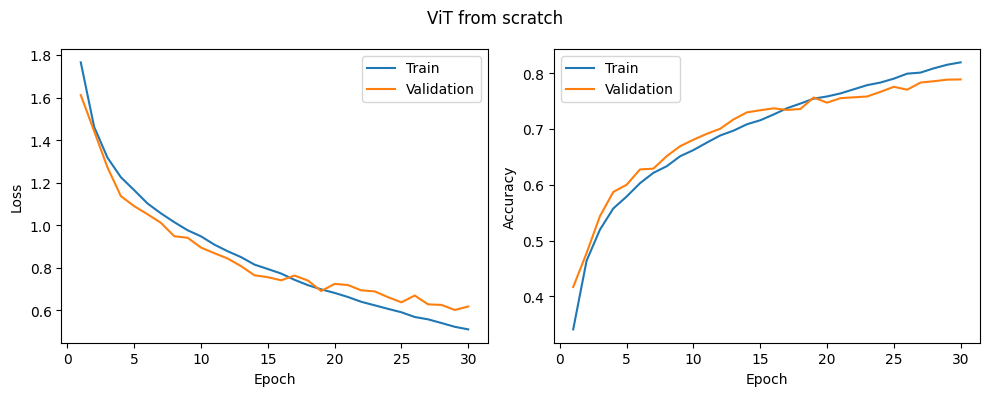

ViT (scratch): final train acc 0.819 | final val acc 0.789 | gap +0.031 | min val loss 0.602 at epoch 29 | final val loss 0.618


In [23]:
def plot_history(hist, title):
    '''Two side-by-side plots: train/val loss and train/val accuracy vs. epoch.'''
    ## YOUR CODE GOES HERE
    epochs=range(1,len(hist['train_loss'])+1)
    fig,axes=plt.subplots(1,2,figsize=(10,4))

    axes[0].plot(epochs,hist['train_loss'],label='Train')
    axes[0].plot(epochs,hist['val_loss'],label='Validation')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()

    axes[1].plot(epochs,hist['train_acc'],label='Train')
    axes[1].plot(epochs,hist['val_acc'],label='Validation')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

def curve_summary(name):
    h = HISTORY[name]
    print(f"{name}: final train acc {h['train_acc'][-1]:.3f} | final val acc {h['val_acc'][-1]:.3f} | "
          f"gap {h['train_acc'][-1] - h['val_acc'][-1]:+.3f} | min val loss {min(h['val_loss']):.3f} at epoch "
          f"{int(np.argmin(h['val_loss'])) + 1} | final val loss {h['val_loss'][-1]:.3f}")

plot_history(HISTORY["ViT (scratch)"], "ViT from scratch"); curve_summary("ViT (scratch)")

###  Interpretation of the ViT curves
*Answer using your own plots and numbers:*
- Where does the train/validation gap open up?
- Does the validation loss keep improving, plateau, or start to rise (overfitting)?
- Is there evidence of underfitting or overfitting?

Both losses go down overall, so the ViT is learning. Around epoch 20, the training accuracy starts to stay above the validation accuracy, and the gap slowly grows. The final training accuracy is 81.92%, while validation accuracy is 78.86%, a difference of 3.06 percentage points. Validation loss still improves overall and is lowest at epoch 29. There are some signs of mild overfitting near the end, but validation loss does not keep rising.

### CNN baseline
Re-run your **Part 1 CNN** (`CIFAR10_CNN`) on the **identical split** and a **comparable epoch budget** using the same `run_experiment` utility, and report its test accuracy. Make sure the Part 1 cell defining `CIFAR10_CNN` has been run.


=== CNN (Part 1) | trainable 815,018 / 815,018 (100.00%) ===
CNN (Part 1) Epoch 1/30 | train loss=1.5385,acc=43.18% | val loss=1.1843,acc=57.72% | time=22.8s
CNN (Part 1) Epoch 2/30 | train loss=1.0954,acc=60.63% | val loss=0.9946,acc=63.44% | time=21.8s
CNN (Part 1) Epoch 3/30 | train loss=0.9157,acc=67.64% | val loss=0.7566,acc=72.80% | time=22.0s
CNN (Part 1) Epoch 4/30 | train loss=0.8057,acc=71.88% | val loss=0.7823,acc=73.44% | time=22.1s
CNN (Part 1) Epoch 5/30 | train loss=0.7377,acc=74.29% | val loss=0.7635,acc=73.24% | time=21.6s
CNN (Part 1) Epoch 6/30 | train loss=0.6779,acc=76.80% | val loss=0.6964,acc=76.56% | time=22.6s
CNN (Part 1) Epoch 7/30 | train loss=0.6301,acc=78.36% | val loss=0.6765,acc=76.84% | time=21.2s
CNN (Part 1) Epoch 8/30 | train loss=0.5951,acc=79.48% | val loss=0.5504,acc=80.82% | time=23.2s
CNN (Part 1) Epoch 9/30 | train loss=0.5556,acc=80.98% | val loss=0.5048,acc=82.82% | time=33.2s
CNN (Part 1) Epoch 10/30 | train loss=0.5256,acc=82.01% | val los

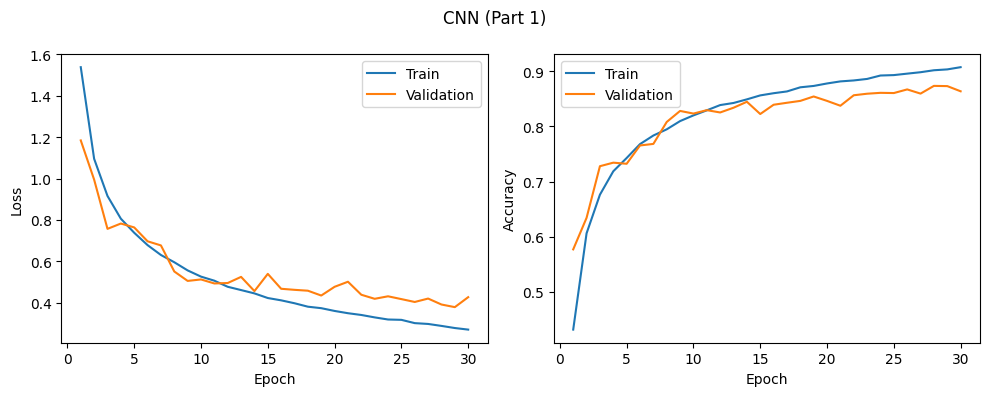

CNN (Part 1): final train acc 0.908 | final val acc 0.864 | gap +0.044 | min val loss 0.378 at epoch 29 | final val loss 0.426

Test accuracy — ViT (scratch): 78.92% | CNN (Part 1): 86.44%


In [24]:
CNN_NAME = "CNN (Part 1)"

set_seed()
# TODO: create a fresh instance of your Part 1 CNN and train it with run_experiment
#       on (train_loader, val_loader, test_loader) for EPOCHS_CNN epochs with LR_CNN.
## YOUR CODE GOES HERE
cnn=CIFAR10_CNN()
run_experiment(CNN_NAME,cnn,(train_loader,val_loader,test_loader),EPOCHS_CNN,LR_CNN)
del cnn
cleanup()

plot_history(HISTORY[CNN_NAME], CNN_NAME); curve_summary(CNN_NAME)
print(f"\nTest accuracy — ViT (scratch): {RESULTS['ViT (scratch)']['test_acc']:.2f}% | {CNN_NAME}: {RESULTS[CNN_NAME]['test_acc']:.2f}%")

###  Why does the scratch ViT do / not do better than the CNN?
*Discuss using your results. Consider, for example, inductive bias (locality, translation equivariance), the size and resolution of CIFAR-10, the amount of information per patch token, and the training budget / augmentation.*

The CNN performs better, with 86.44% test accuracy compared with 78.92% for the scratch ViT. CNNs are designed to pick up local patterns, such as edges and textures and reuse the same filters across an image. It seems helpful for small CIFAR-10 images. The ViT uses 64 patches of size 4 * 4 and learns how the patches relate to each other. Each patch has limited detail because the images are only 32 * 32. With 45000 training images and 30 epochs, the CNN works better in this setup. The ViT might improve with more data, stronger augmentation or a different training schedule.

## 4. ImageNet-pretrained ViT and linear-probe baseline  *(Rubric 4)*

Load `google/vit-base-patch16-224-in21k` (ViT-Base, 16×16 patches, 224×224 input, pretrained on ImageNet-21k) with `ViTForImageClassification`, replacing its head with a **new 10-class head** (the Hugging Face warning about newly initialised `classifier` weights is expected).

- Normalize inputs with the checkpoint's **own** mean/std (from `ViTImageProcessor`).
- Resize CIFAR-10 images to **224×224**. *Tip:* keeping images at 32×32 in the DataLoader and resizing on the GPU inside the model wrapper (`F.interpolate`, bilinear) is much faster than resizing with PIL on the CPU.

**Linear probe:** freeze the **entire backbone** and train only the new head for 1–2 epochs, then report the test accuracy.

In [25]:
from transformers import ViTForImageClassification, ViTImageProcessor

proc = ViTImageProcessor.from_pretrained(PT_NAME)
# TODO: get the normalization mean/std expected by the pretrained model from `proc`
## YOUR CODE GOES HERE
PT_MEAN,PT_STD=proc.image_mean,proc.image_std
print("pretrained normalisation:", PT_MEAN, PT_STD, "| expected input size:", proc.size)

pt_loaders = make_loaders(PT_MEAN, PT_STD, [T.RandomHorizontalFlip()], PT_BATCH, PT_N_TRAIN, PT_N_VAL, PT_N_TEST)
print(f"pretrained-model data: train {len(pt_loaders[0].dataset)} | val {len(pt_loaders[1].dataset)} | test {len(pt_loaders[2].dataset)} | batch {PT_BATCH}")


class HFViT(nn.Module):
    '''Resizes 32x32 -> 224x224, then runs a Hugging Face ViT (optionally LoRA-wrapped) and returns logits.'''
    def __init__(self, hf_model):
        super().__init__(); self.m = hf_model

    def forward(self, x):
        # TODO: resize x to 224x224 and return the logits of self.m
        ## YOUR CODE GOES HERE
        x=F.interpolate(x,size=(224,224),mode="bilinear",align_corners=False)
        return self.m(pixel_values=x).logits


def load_pretrained_vit():
    '''Returns a fresh ViTForImageClassification loaded from PT_NAME with a new 10-class head.'''
    set_seed()   # same head initialisation for every run
    ## YOUR CODE GOES HERE
    return ViTForImageClassification.from_pretrained(
        PT_NAME,
        num_labels=10,
        ignore_mismatched_sizes=True
    )

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

pretrained normalisation: (0.5, 0.5, 0.5) (0.5, 0.5, 0.5) | expected input size: SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
pretrained-model data: train 45000 | val 5000 | test 10000 | batch 64


In [26]:
lp_hf = load_pretrained_vit()
# TODO: freeze the entire backbone so that only the new classification head is trainable
## YOUR CODE GOES HERE
for p in lp_hf.parameters():
    p.requires_grad=False

for p in lp_hf.classifier.parameters():
    p.requires_grad=True
print("trainable tensors:", [n for n, p in lp_hf.named_parameters() if p.requires_grad])
run_experiment("Linear probe", HFViT(lp_hf), pt_loaders, EPOCHS_LP, LR_LP)
del lp_hf; cleanup()

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable tensors: ['classifier.weight', 'classifier.bias']

=== Linear probe | trainable 7,690 / 85,806,346 (0.01%) ===
Linear probe Epoch 1/2 | train loss=0.2223,acc=95.76% | val loss=0.1252,acc=96.50% | time=127.8s
Linear probe Epoch 2/2 | train loss=0.1039,acc=96.90% | val loss=0.1139,acc=96.56% | time=130.8s
--> Linear probe: test acc 96.35% | 129.3 s/epoch | peak mem 1036 MB


## 5. LoRA fine-tuning (with `peft`) vs. full fine-tuning  *(Rubric 5)*

**LoRA.** Using `peft`, inject low-rank adapters (`W + (α/r)·B·A`) into the attention projections of every encoder layer — the **query** and **value** projections for the Hugging Face ViT (`query`/`value`, or `q_proj`/`v_proj` in transformers ≥ 5; `attention_qv_names` detects which). Use a rank such as **r = 8 or 16** (`LORA_R` in the config cell). The pretrained weights stay frozen; keep the new 10-class `classifier` **fully trainable** (hint: `modules_to_save`). Fine-tune for 2–3 epochs.

**Full fine-tuning.** Same model, same data, batch size and epoch budget, with **all** parameters trainable and a small learning rate.

For both, report: trainable parameters (and % of total), time per epoch, peak GPU memory and test accuracy (`run_experiment` records all four).

 **State your LoRA configuration here** (rank, α, dropout, target modules, learning rate, epochs).

 I used LoRA rank 8, alpha 16 and dropout 0.1, targeting the query and value attention projections. The classification head remained trainable. The learning rate was 0.001, with 3 training epochs.

In [27]:
# Workaround for a torchao / peft incompatibility on some Colab images
!pip uninstall -y -q torchao

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


LoRA target modules: ('q_proj', 'v_proj')
trainable params: 302,602 || all params: 86,108,948 || trainable%: 0.3514

=== LoRA (r=8) | trainable 302,602 / 86,108,948 (0.35%) ===
LoRA (r=8) Epoch 1/3 | train loss=0.1423,acc=97.32% | val loss=0.0440,acc=98.68% | time=323.1s
LoRA (r=8) Epoch 2/3 | train loss=0.0322,acc=99.04% | val loss=0.0529,acc=98.40% | time=319.9s
LoRA (r=8) Epoch 3/3 | train loss=0.0202,acc=99.41% | val loss=0.0447,acc=98.68% | time=319.1s
--> LoRA (r=8): test acc 98.40% | 320.7 s/epoch | peak mem 4042 MB


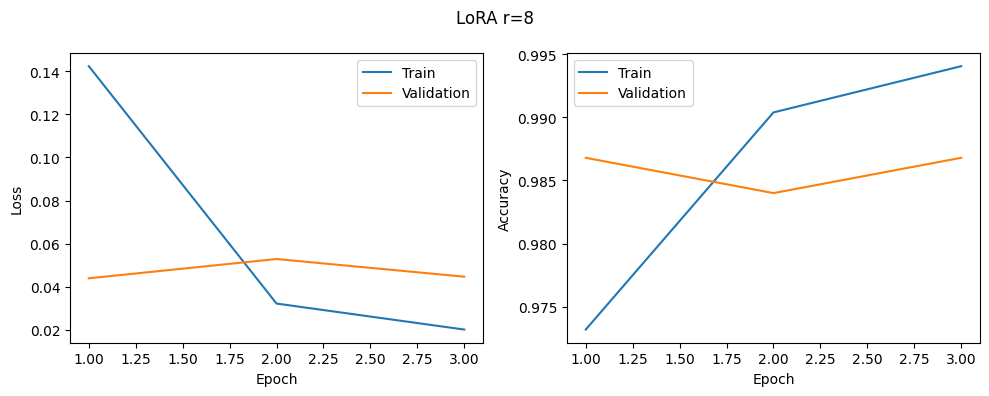

LoRA (r=8): final train acc 0.994 | final val acc 0.987 | gap +0.007 | min val loss 0.044 at epoch 1 | final val loss 0.045


In [28]:
from peft import LoraConfig, get_peft_model

def attention_qv_names(hf_model):
    '''Names of the query/value projections: `query`/`value` (transformers 4.x) or `q_proj`/`v_proj` (5.x).'''
    leaf = {n.split(".")[-1] for n, _ in hf_model.named_modules()}
    return ("query", "value") if "query" in leaf else ("q_proj", "v_proj")

def make_lora_vit(r, targets=None):
    '''Returns an HFViT wrapping a LoRA-adapted pretrained ViT with rank r.'''
    base = load_pretrained_vit()
    targets = targets or attention_qv_names(base)
    # TODO: build a LoraConfig (rank r, lora_alpha, lora_dropout, target_modules=targets,
    #       and keep the "classifier" head trainable), then wrap `base` with get_peft_model.
    ## YOUR CODE GOES HERE
    config=LoraConfig(
        r=r,
        lora_alpha=2*r,
        lora_dropout=0.1,
        target_modules=list(targets),
        modules_to_save=["classifier"],
        bias="none"
    )
    peft_model=get_peft_model(base,config)

    print("LoRA target modules:", targets); peft_model.print_trainable_parameters()
    return HFViT(peft_model)

lora = make_lora_vit(LORA_R)
run_experiment(f"LoRA (r={LORA_R})", lora, pt_loaders, EPOCHS_FT, LR_LORA, weight_decay=0.01)
plot_history(HISTORY[f"LoRA (r={LORA_R})"], f"LoRA r={LORA_R}"); curve_summary(f"LoRA (r={LORA_R})")
del lora; cleanup()

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



=== Full fine-tuning | trainable 85,806,346 / 85,806,346 (100.00%) ===
Full fine-tuning Epoch 1/3 | train loss=0.5696,acc=94.01% | val loss=0.1645,acc=98.32% | time=406.7s
Full fine-tuning Epoch 2/3 | train loss=0.0997,acc=99.05% | val loss=0.0943,acc=98.44% | time=401.9s
Full fine-tuning Epoch 3/3 | train loss=0.0399,acc=99.64% | val loss=0.0881,acc=97.94% | time=401.4s
--> Full fine-tuning: test acc 98.04% | 403.4 s/epoch | peak mem 5825 MB


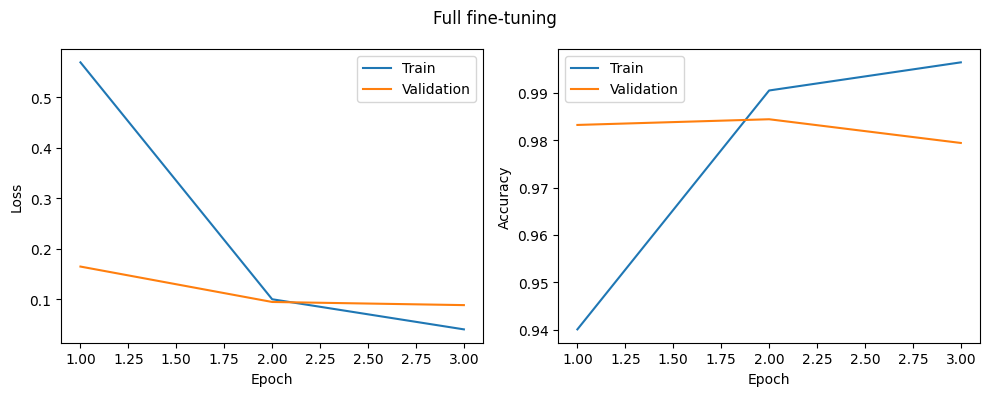

Full fine-tuning: final train acc 0.996 | final val acc 0.979 | gap +0.017 | min val loss 0.088 at epoch 3 | final val loss 0.088


In [29]:
# Full fine-tuning: same epoch budget as LoRA.
# If this cell runs out of memory, lower PT_BATCH (or PT_N_TRAIN) in the config cell and state it in your report.
# TODO: load a fresh pretrained ViT (all parameters trainable), wrap it in HFViT and
#       train it with run_experiment under the name "Full fine-tuning" (EPOCHS_FT epochs, LR_FULL).
## YOUR CODE GOES HERE
full_hf=load_pretrained_vit()

for p in full_hf.parameters():
    p.requires_grad=True

full_model=HFViT(full_hf)
run_experiment("Full fine-tuning",full_model,pt_loaders,EPOCHS_FT,LR_FULL)

del full_model,full_hf

plot_history(HISTORY["Full fine-tuning"], "Full fine-tuning"); curve_summary("Full fine-tuning")
cleanup()

## 6. Results comparison  *(Rubric 6)*
Summarize **all** models in a single table: ViT from scratch, CNN, linear probe, LoRA fine-tuning and full fine-tuning. Include at least **test accuracy, trainable parameters (and %), time per epoch and peak GPU memory** for each (all stored in `RESULTS`).

In [30]:
ORDER = ["ViT (scratch)", CNN_NAME, "Linear probe", f"LoRA (r={LORA_R})", "Full fine-tuning"]

def results_table(names):
    '''Return a pandas DataFrame with one row per model in `names` (skip names not in RESULTS).'''
    ## YOUR CODE GOES HERE
    return pd.DataFrame([RESULTS[name] for name in names if name in RESULTS],index=[name for name in names if name in RESULTS])

summary = results_table(ORDER)
display(summary)
summary.to_csv("results_summary.csv")

,test_acc,val_acc,trainable,total,pct_trainable,sec_per_epoch,peak_mem_mb,epochs
ViT (scratch),78.92,78.86,4249354,4249354,100.000000,36.794931,677.686523,30
CNN (Part 1),86.44,86.38,815018,815018,100.000000,22.447889,131.134766,30
Linear probe,96.35,96.56,7690,85806346,0.008962,129.287370,1035.605469,2
LoRA (r=8),98.40,98.68,302602,86108948,0.351418,320.711306,4041.571289,3
Full fine-tuning,98.04,97.94,85806346,85806346,100.000000,403.357375,5824.648926,3


### Confusion matrices on the validation set — ViT (scratch) vs. LoRA ViT
Implement `plot_confusions` to plot one confusion matrix per model (side by side), with class names on both axes. Validation predictions and labels are stored in `VAL_PREDS[name]`. `top_confusions` (provided) lists the most frequent (true → predicted) errors.

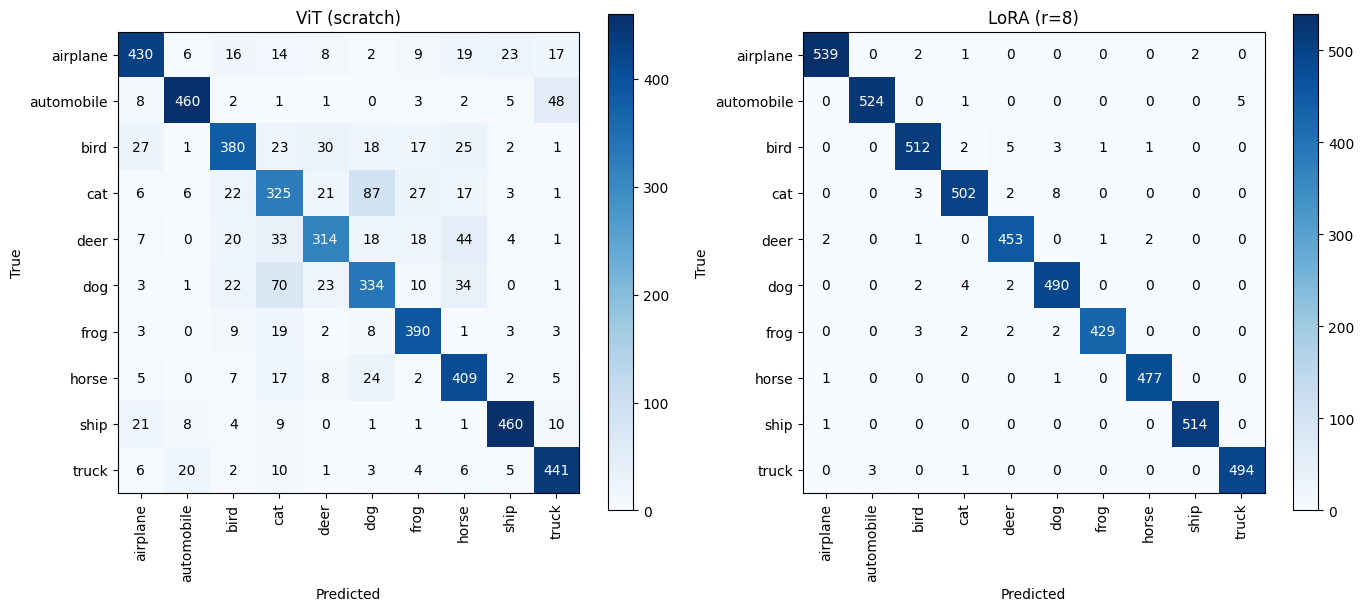

ViT (scratch) - most frequent errors (true -> predicted): cat->dog (87); dog->cat (70); automobile->truck (48); deer->horse (44); dog->horse (34)
LoRA (r=8) - most frequent errors (true -> predicted): cat->dog (8); bird->deer (5); automobile->truck (5); dog->cat (4); truck->automobile (3)


In [31]:
def plot_confusions(names):
    '''Plot the validation confusion matrix of each model in `names` side by side.'''
    ## YOUR CODE GOES HERE
    fig,axes=plt.subplots(1,len(names),figsize=(7*len(names),6),squeeze=False)
    for ax,name in zip(axes[0],names):
        pred,lab=VAL_PREDS[name]
        cm=confusion_matrix(lab,pred,labels=range(10))
        im=ax.imshow(cm,cmap="Blues")
        ax.set_title(name)
        ax.set_xticks(range(10))
        ax.set_yticks(range(10))
        ax.set_xticklabels(CLASSES,rotation=90)
        ax.set_yticklabels(CLASSES)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("True")
        for i in range(10):
            for j in range(10):
                ax.text(j,i,str(cm[i,j]),ha="center",va="center",color="white" if cm[i,j]>cm.max()/2 else "black")
        fig.colorbar(im,ax=ax)
    plt.tight_layout()
    plt.show()

def top_confusions(name, k=5):
    pred, lab = VAL_PREDS[name]
    cm = confusion_matrix(lab, pred, labels=range(10)); np.fill_diagonal(cm, 0)
    pairs = sorted(((cm[i, j], CLASSES[i], CLASSES[j]) for i in range(10) for j in range(10) if cm[i, j]), reverse=True)[:k]
    print(f"{name} - most frequent errors (true -> predicted): " + "; ".join(f"{t}->{p} ({c})" for c, t, p in pairs))

CM_NAMES = ["ViT (scratch)", f"LoRA (r={LORA_R})"]
plot_confusions(CM_NAMES)
for n in CM_NAMES: top_confusions(n)

###  How do the confusion patterns differ?
*Compare the two confusion matrices: how many errors each model makes, which class pairs are confused, and whether the errors are spread out or concentrated. Suggest reasons for the differences.*

The scratch ViT makes 1,057 mistakes on the validation set, while LoRA makes only 66. The ViT confuses several class pairs, especially cats and dogs, automobiles and trucks, and deer and horses. For example, it predicts dog for 87 cat images, compared with only 8 for LoRA. Automobile→truck errors also drop from 48 to 5. LoRA still makes some mistakes between similar-looking objects, but there are far fewer overall. This suggests that the pretrained model has learned more useful visual features.

### Misclassified validation images — LoRA model
Show a grid of **at least 16** misclassified validation images from the LoRA model, with the **predicted and true** label on each.

*Hint:* the validation loader is not shuffled, so position `i` in `VAL_PREDS[name]` corresponds to `VAL_IDX[i]`, and `raw_train.data[VAL_IDX[i]]` gives the un-normalized image.

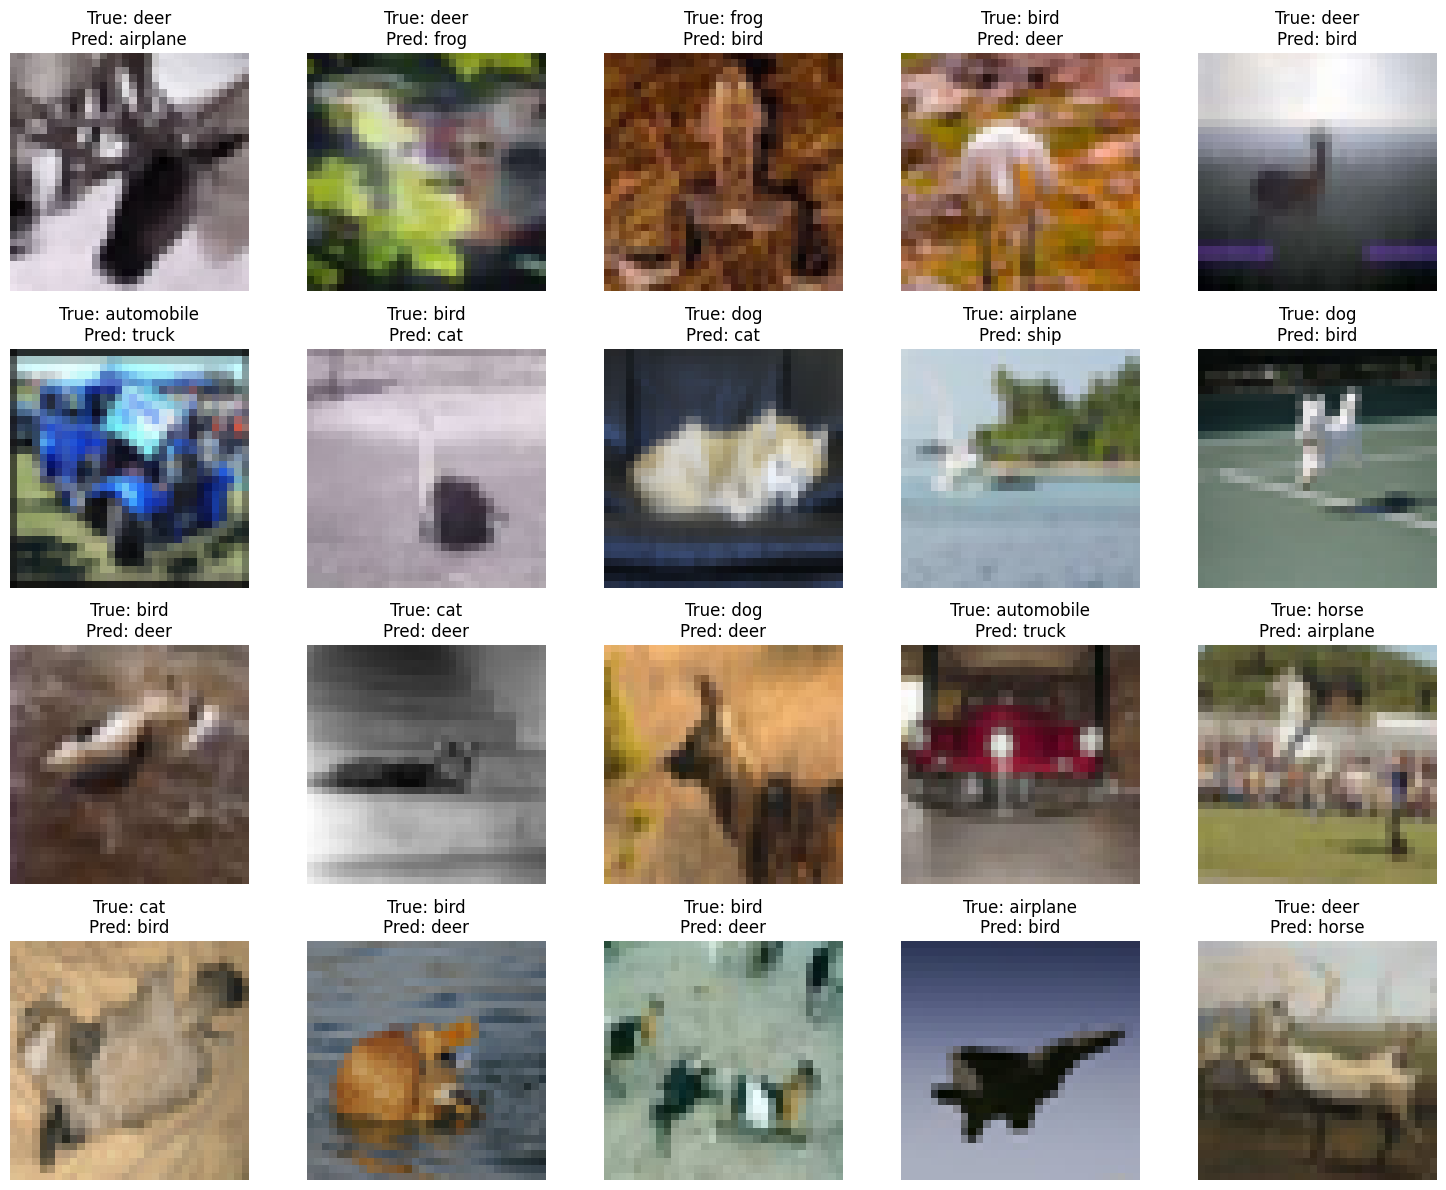

In [32]:
def show_misclassified(name, n=20, cols=5):
    '''Grid of n misclassified validation images from model `name`, titled with predicted and true labels.'''
    ## YOUR CODE GOES HERE
    pred,lab=VAL_PREDS[name]
    wrong=np.where(pred!=lab)[0][:n]
    rows=math.ceil(len(wrong)/cols)
    fig,axes=plt.subplots(rows,cols,figsize=(3*cols,3*rows),squeeze=False)
    for ax in axes.flat:
        ax.axis("off")

    for ax,i in zip(axes.flat,wrong):
        ax.imshow(raw_train.data[VAL_IDX[i]])
        ax.set_title(f"True: {CLASSES[lab[i]]}\nPred: {CLASSES[pred[i]]}")

    plt.tight_layout()
    plt.show()
show_misclassified(f"LoRA (r={LORA_R})")

###  What do the misclassified LoRA images have in common?
*Describe the images in your grid and any patterns you see (e.g. particular class pairs, framing, ambiguity).*

Many of these images are blurry, show only part of the object, or have distracting backgrounds. Some objects are small or shown from unusual angles. For example, a close-up deer is predicted as an airplane, and some dogs are predicted as cats or deer. Automobiles are also mistaken for trucks. Resizing the images to 224 * 224 makes them bigger, but it does not bring back details missing from the original 32 * 32 pictures.

###  Cost/accuracy discussion
*Using your results table, compare the linear probe, LoRA and full fine-tuning (and the from-scratch models) in terms of accuracy, trainable parameters, time per epoch and peak GPU memory.*

The linear probe gives 96.35% test accuracy while training only 7690 parameters, or about 0.009% of the model. It is the fastest pretrained method, taking 129.3 seconds per epoch and 1035.6 MB of peak GPU memory. LoRA rank 8 improves accuracy to 98.40%, with 302602 trainable parameters, or 0.351%. It takes 320.7 seconds per epoch and 4041.6 MB. Full fine-tuning trains 85806346 parameters, but its accuracy is slightly lower at 98.04%. It also takes longer and uses more memory: 403.4 seconds per epoch and 5824.6 MB. In these runs, LoRA gives the best balance of accuracy and cost. The scratch models are faster per epoch, but they need 30 epochs and get lower accuracy. The cost of the earlier ImageNet pretraining is not included in this comparison.

## 7. Controlled experiment  *(Rubric 7)*

Make **one** deliberate change to the fine-tuning setup and re-run it, keeping everything else identical. Examples:
- LoRA rank (e.g. r = 4 vs. r = 32),
- target modules (attention only vs. attention + MLP layers),
- learning rate,
- amount of training data (e.g. 10% of the training set for both the from-scratch ViT and the LoRA model).

 **Change made:** *describe the change.*
 I changed the LoRA rank from 8 to 16. I kept alpha at 16 and used the same dropout, target modules, learning rate, data and number of epochs.

 **Hypothesis (write this BEFORE running):** *what do you expect to happen to accuracy, trainable parameters and cost, and why?*
 I expect rank 16 to have more trainable parameters and use slightly more memory. It might improve accuracy because the adapters can learn more complex changes, but a higher rank may not always help.

In [33]:
CTRL_NAME="LoRA (r=16)"   # e.g. "LoRA (r=32)"

# TODO: build the modified model/setup, train it with run_experiment under CTRL_NAME,
#       then compare it with the baseline LoRA run (e.g. results_table([f"LoRA (r={LORA_R})", CTRL_NAME])).
## YOUR CODE GOES HERE
set_seed()
base=load_pretrained_vit()
targets=attention_qv_names(base)

config=LoraConfig(
    r=16,
    lora_alpha=2*LORA_R,
    lora_dropout=0.1,
    target_modules=list(targets),
    modules_to_save=["classifier"],
    bias="none"
)

ctrl_model=HFViT(get_peft_model(base,config))
run_experiment(
    CTRL_NAME,ctrl_model,pt_loaders,
    EPOCHS_FT,LR_LORA,weight_decay=0.01
)

display(results_table([f"LoRA (r={LORA_R})",CTRL_NAME]))
del ctrl_model,base
cleanup()

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



=== LoRA (r=16) | trainable 597,514 / 86,403,860 (0.69%) ===
LoRA (r=16) Epoch 1/3 | train loss=0.1428,acc=97.36% | val loss=0.0503,acc=98.30% | time=322.6s
LoRA (r=16) Epoch 2/3 | train loss=0.0321,acc=99.02% | val loss=0.0562,acc=98.32% | time=321.6s
LoRA (r=16) Epoch 3/3 | train loss=0.0198,acc=99.40% | val loss=0.0695,acc=97.90% | time=318.2s
--> LoRA (r=16): test acc 98.00% | 320.8 s/epoch | peak mem 4050 MB


,test_acc,val_acc,trainable,total,pct_trainable,sec_per_epoch,peak_mem_mb,epochs
LoRA (r=8),98.4,98.68,302602,86108948,0.351418,320.711306,4041.571289,3
LoRA (r=16),98.0,97.90,597514,86403860,0.691536,320.807521,4050.125977,3


 **Result:** *report what actually happened and compare it with your hypothesis. If it did not match, explain why.*

 Rank 16 increased the trainable parameters from 302,602 to 597,514. Memory increased slightly from 4,041.6 to 4,050.1 MB, while training time stayed almost the same at about 320.8 seconds per epoch. However, test accuracy dropped from 98.40% to 98.00%. The extra capacity did not help in this run, and rank 8 may already be enough for this task. Each setup was only tested once, so this does not show that rank 16 is always worse. The reused data loader also did not give exactly the same batch order. Since alpha stayed at 16, changing the rank also changed alpha/r.

## Final summary table (all models + controlled experiment)

In [34]:
final = results_table(ORDER + [CTRL_NAME])
display(final)
final.to_csv("results_summary_all.csv")

,test_acc,val_acc,trainable,total,pct_trainable,sec_per_epoch,peak_mem_mb,epochs
ViT (scratch),78.92,78.86,4249354,4249354,100.000000,36.794931,677.686523,30
CNN (Part 1),86.44,86.38,815018,815018,100.000000,22.447889,131.134766,30
Linear probe,96.35,96.56,7690,85806346,0.008962,129.287370,1035.605469,2
LoRA (r=8),98.40,98.68,302602,86108948,0.351418,320.711306,4041.571289,3
Full fine-tuning,98.04,97.94,85806346,85806346,100.000000,403.357375,5824.648926,3
LoRA (r=16),98.00,97.90,597514,86403860,0.691536,320.807521,4050.125977,3


## ✏️ Conclusions
*Summarize your main findings from Part 2.*

The CNN worked better than the scratch ViT, reaching 86.44% test accuracy compared with 78.92%. Pretraining made a big difference: even training only the new classification head gave 96.35%. LoRA rank 8 gave the highest accuracy of 98.40% while training only 0.351% of the parameters. It also used less time and memory than full fine-tuning. Increasing the rank to 16 did not improve the result. Overall, LoRA rank 8 gave the best balance of accuracy and training cost in my experiments.

### Notes on Part 2 - Check that:
- [ ] The same 45k / 5k / 10k split is used for every model, and it is documented in section 1
- [ ] Both ViT sanity checks (tiny-batch overfit and tensor shapes) are shown
- [ ] Any change to `PT_N_TRAIN` / `PT_BATCH` (e.g. for full fine-tuning memory) is stated in the report
- [ ] All cells run top to bottom without errors, with outputs and plots visible
- [ ] AI assistance (if any) is documented in the report